# Homework11

Exercises with text processing and NLP modeling

## Goals

- Understand similarities and differences between the processes of working with text, images and tabular data
- Practice with different methods of encoding and modeling text data
- See different methods for extracting information or patterns from text datasets

### Setup

Run the following 2 cells to import all necessary libraries and helpers for this homework.

In [1]:
!wget -q "https://github.com/PSAM-5020-2026F-A/5020-utils/raw/main/src/data_utils.py" -O data_utils.py
!wget -q "https://github.com/PSAM-5020-2026F-A/5020-utils/raw/main/src/text_utils.py" -O text_utils.py

In [2]:
import matplotlib.cm as cm
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

from data_utils import display_silhouette_plots, object_from_json_url
from text_utils import get_top_words

You can tell it's gonna be a good homework from the number of imports.
# 🙃

## Cheat Sheet

There are lots of conversions in this homework between lists, strings, vectors, scores, etc...

This list can help as a quick reference for the names of the functions and what they expect as input, and produce as output.

These all operate on lists of _something_ and return lists of _something else_. But, here, let's just focus on the _type_ of the elements that go in these lists. Most of them will work on single elements, but not all.

`TFIDF.fit_transform(string)` / `TFIDF.transform(string)` : string -> sparse vector

`TFIDF.inverse_transform(vector)` : sparse vector -> list of words (NOT a string)

`TFIDF.get_feature_names_out()` : None -> list of words (vocab of dataset)

`TFIDF.get_feature_names_out()[idx]` : int (column index / word id) -> word

`vector.toarray()` : vector -> regular array

`get_top_words(vector, vocab, n_words=N)` : vector + list of all words + int -> list of top-N words in vector

`argsort(metric)` : list of floats -> list of int indexes

For example:

To get the words in a sentence ordered by importance (most important first), we have to turn a string into a vector, then the vector into a regular list of scores, then the list into indexes, and, finally, fetch words from our vocab list using these indexes.

```py
sentence = "a sentence goes here"
num_words = len(sentence.split(" "))
sentence_vct = TFIDF.transform([sentence])
sentence_vct_list = sentence_vct.toarray()
idx_by_importance = argsort(sentence_vct_list, reverse=True)[:num_words]
TFIDF.get_feature_names_out()[idx_by_importance]
```

For this particular example we could've used the `get_top_words()` function to get words ordered by importance:

```py
sentence = "a sentence goes here"
num_words = len(sentence.split(" "))

get_top_words(
  TFIDF.transform([sentence]),
  TFIDF.get_feature_names_out(),
  n_words=num_words
)
```

## Have protein, need seasoning

Let's create a model to help us season our foods. In the end, what we want is a model that receives a short list of ingredients and returns a list of seasonings or complementary ingredients for our original ingredients list.

In order to do that we need a dataset of recipes. We'll load that into a text dataset where each recipe is a document and the ingredients are our document *tokens*.

Let's take a look at the recipe dataset and become familiar with the data and how it's organized.

We'll load our recipes and do a bit of exploratory data analysis to look for patterns first to see if this kind of modeling makes any sense.

### Load Data

Here's our dataset. Let's load it into an object for inspection:

In [3]:
DATA_PATH = "https://raw.githubusercontent.com/PSAM-5020-2026F-A/5020-utils/refs/heads/main/datasets/text/recipes/recipes_min16.json"
recipes_obj = object_from_json_url(DATA_PATH)

### Look at Data

How's the data organized?

How many recipes do we have?

Do all recipes have the same number of ingredients?

Anything else stand out about the data?

In [8]:
# TODO: Look at Data here
print("Type of recipes_obj:", type(recipes_obj))

first_recipe = recipes_obj[0]
print("Type of one recipe:", type(first_recipe))
print("First recipe:", first_recipe)

# TODO: How many recipes
num_recipes = len(recipes_obj)
print("Number of recipes:", num_recipes)

# TODO: How many ingredients do the shortest and longest recipes have?
ingredient_counts = []
for recipe in recipes_obj:
    ingredient_list = recipe["ingredients"]
    num_ingredients = len(ingredient_list)
    ingredient_counts.append(num_ingredients)

shortest_recipe_length = min(ingredient_counts)
longest_recipe_length = max(ingredient_counts)
print("Shortest recipe has", shortest_recipe_length, "ingredients")
print("Longest recipe has", longest_recipe_length, "ingredients")

unique_counts = set(ingredient_counts)
print("Number of different recipe lengths:", len(unique_counts))

Type of recipes_obj: <class 'list'>
Type of one recipe: <class 'dict'>
First recipe: {'id': 18009, 'ingredients': ['eggs', 'sugar', 'milk', 'flour', 'baking powder', 'raisins']}
Number of recipes: 5026
Shortest recipe has 5 ingredients
Longest recipe has 27 ingredients
Number of different recipe lengths: 21


### Create Input Features

Our dataset doesn't really have to be a `DataFrame` here. It can, but it doesn't have to be.

Each recipe right now is described as a list of ingredients, but what we really want is a list of *sentences*, where each *sentence* is a Python `string` with all of the ingredients for a given recipe.

Instead of:<br>```["salt", "baking soda", "water", "mushroom"]```,

we want:<br>```"salt baking soda water mushroom"```

The `join()` function might help.

Another thing to consider is wether we want to do anything special about multi-word ingredients, like *baking soda*.

Do we want to let our vectorizer split that into two tokens, or do we want to guarantee that *baking* and *soda* always stay together? 

In [9]:
# TODO: turn list of objects into list of strings
recipe_strings = []
for recipe in recipes_obj:
    ingredient_list = recipe["ingredients"]

    joined_ingredients = []
    for ingredient in ingredient_list:
        joined_ingredient = ingredient.replace(" ", "_")
        joined_ingredients.append(joined_ingredient)

    recipe_string = " ".join(joined_ingredients)
    recipe_strings.append(recipe_string)

print("Number of strings:", len(recipe_strings))
print("First recipe string:", recipe_strings[0])

Number of strings: 5026
First recipe string: eggs sugar milk flour baking_powder raisins


### Encode Data

The fun part.

Let's vectorize our list of ingredient strings into a sparse document matrix using `CountVectorizer` or `TfidfVectorizer`.

The resulting matrix will have one row for each recipe, and the columns will encode the ingredients.

In [10]:
# TODO: Vectorize ingredients from our recipe list
TFIDF = TfidfVectorizer()
recipe_vectors = TFIDF.fit_transform(recipe_strings)
print("Matrix shape:", recipe_vectors.shape)

# TODO: How many words are in our vocabulary?
vocab = TFIDF.get_feature_names_out()
vocab_size = len(vocab)
print("Vocabulary size:", vocab_size)

first_ten_words = vocab[:10]
print("First ten words:", first_ten_words)

Matrix shape: (5026, 519)
Vocabulary size: 519
First ten words: ['adobo_sauce' 'agave' 'allspice' 'almond' 'almonds' 'amchur'
 'american_cheese' 'ancho_chile_pepper' 'ancho_powder' 'anchovy']


### Cluster Data

Now that we have our recipes/documents vectorized we can study them a little bit, and look for patterns.

What happens if we cluster our recipes ? What do the cluster centers represent ?

When might this be useful ?

In [11]:
# TODO: cluster recipes
num_clusters = 10
kmeans_model = KMeans(n_clusters=num_clusters, random_state=42)
cluster_labels = kmeans_model.fit_predict(recipe_vectors)

cluster_centers = kmeans_model.cluster_centers_
print("Cluster centers shape:", cluster_centers.shape)

recipes_per_cluster = []
for cluster_id in range(num_clusters):
    cluster_size = (cluster_labels == cluster_id).sum()
    recipes_per_cluster.append(cluster_size)
print("Recipes per cluster:", recipes_per_cluster)

Cluster centers shape: (10, 519)
Recipes per cluster: [np.int64(505), np.int64(394), np.int64(1122), np.int64(382), np.int64(328), np.int64(440), np.int64(550), np.int64(621), np.int64(298), np.int64(386)]


### Cluster Centers

Use the `get_top_words()` function to decode the `cluster_centers` back into ingredients.

In [13]:
# TODO: Look at cluster centers
all_top_words = get_top_words(cluster_centers, vocab, n_words=10)

for cluster_id in range(num_clusters):
    cluster_words = all_top_words[cluster_id]
    print("Cluster", cluster_id, ":", cluster_words)

Cluster 0 : ['parmesan_cheese', 'olive_oil', 'garlic', 'salt', 'basil', 'black_pepper', 'mozzarella_cheese', 'butter', 'parsley', 'tomatoes']
Cluster 1 : ['ginger', 'masala', 'coriander', 'cumin', 'onions', 'garlic', 'salt', 'turmeric', 'yogurt', 'cumin_seed']
Cluster 2 : ['salt', 'onions', 'garlic', 'black_pepper', 'rice', 'pepper', 'butter', 'onion', 'thyme', 'water']
Cluster 3 : ['tortilla', 'cheddar_cheese', 'sour_cream', 'salsa', 'chili', 'black_bean', 'cilantro', 'rice', 'onion', 'tomatoes']
Cluster 4 : ['vanilla', 'sugar', 'milk', 'butter', 'egg', 'eggs', 'flour', 'cinnamon', 'salt', 'chocolate']
Cluster 5 : ['flour', 'eggs', 'butter', 'baking_powder', 'milk', 'salt', 'sugar', 'buttermilk', 'yeast', 'baking_soda']
Cluster 6 : ['soy_sauce', 'sesame_oil', 'ginger', 'sugar', 'vinegar', 'garlic', 'corn_starch', 'rice', 'onion', 'sesame_seeds']
Cluster 7 : ['olive_oil', 'garlic', 'tomatoes', 'wine', 'parsley', 'basil', 'salt', 'black_pepper', 'oregano', 'lemon_juice']
Cluster 8 : ['f

### Interpretation

<span style="color:hotpink">
What do these cluster centers represent ?<br>
Is there anything interesting about recipe cluster centers ?<br>
</span>

Each cluster center is the "average recipe" of its group: a vector with one TF-IDF score for every ingredient in the vocabulary. Decoding the top-scoring ingredients with get_top_words shows which ingredients define each cluster.

What is interesting is that KMeans was never told anything about cuisines or recipe types, only which ingredients appear together, yet the clusters match real categories. For example, cluster 1 (ginger, masala, coriander, cumin, turmeric) is Indian, cluster 3 (tortilla, salsa, black bean) is Tex-Mex, cluster 6 (soy sauce, sesame oil, ginger) is East Asian and cluster 8 (fish sauce, coconut milk, lime juice) is Southeast Asian. There are also two baking clusters one for sweet desserts (vanilla, chocolate, cinnamon) and one for breads and cakes (yeast, baking powder, buttermilk). Similar cuisines also overlap a bit, clusters 3 and 9 share cilantro, chili, and cumin, and clusters 0 and 7 share olive oil, garlic and basil. Cluster 2 (salt, onions, garlic, black pepper, rice) is the largest at 1122 recipes and looks like a general-purpose group of staples that don't point to one cuisine. Ingredients also repeat across clusters (garlic, salt, and onion show up in many) which is expected since they're used in almost every cuisine. This shows that ingredient lists carry enough information to separate recipe types, which is what makes recommending complementary seasonings possible.

### Plot Clusters

Let's plot our clusters to see if we have to adjust any of the clustering parameters.

Since we can't plot in $500$ dimensions, we should use `TruncatedSVD` to look at our clusters in $2D$ and $3D$.

Variance kept in 2D: 0.037763048920708905
Variance kept in 3D: 0.06048367043576856


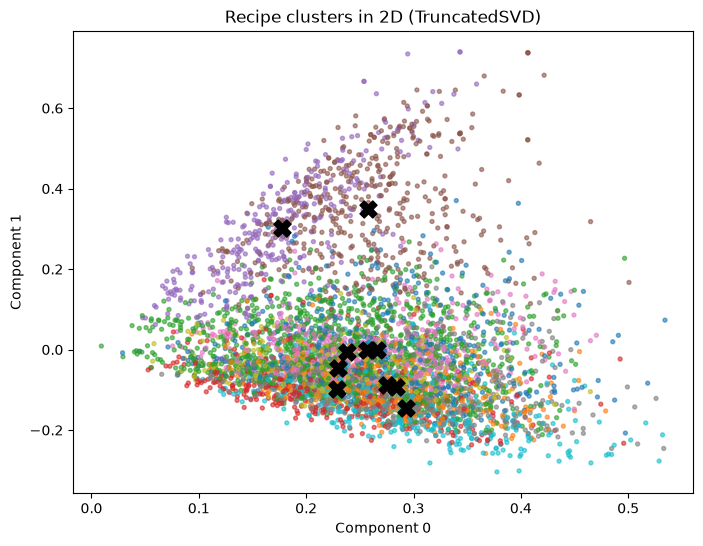

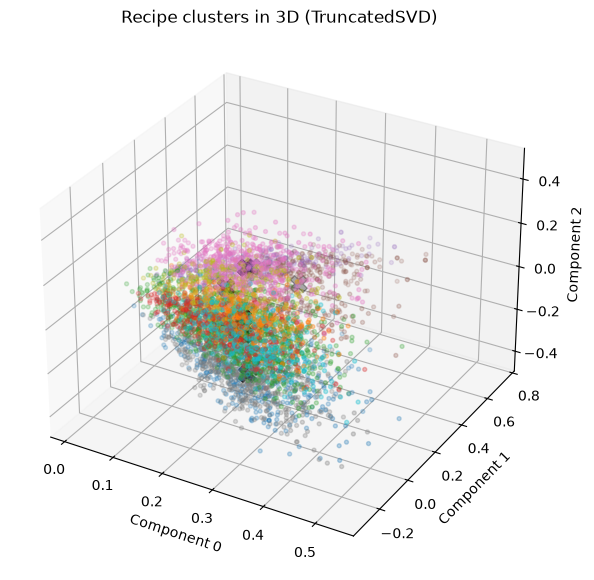

In [17]:
# TODO: TruncatedSVD to reduce the dimensions of our feature space
svd_2d = TruncatedSVD(n_components=2, random_state=42)
points_2d = svd_2d.fit_transform(recipe_vectors)
centers_2d = svd_2d.transform(cluster_centers)

svd_3d = TruncatedSVD(n_components=3, random_state=42)
points_3d = svd_3d.fit_transform(recipe_vectors)
centers_3d = svd_3d.transform(cluster_centers)

variance_2d = svd_2d.explained_variance_ratio_.sum()
variance_3d = svd_3d.explained_variance_ratio_.sum()
print("Variance kept in 2D:", variance_2d)
print("Variance kept in 3D:", variance_3d)

# TODO: plot clusters
# 2D plot
figure_2d = plt.figure(figsize=(8, 6))
x_values = points_2d[:, 0]
y_values = points_2d[:, 1]
plt.scatter(x_values, y_values, c=cluster_labels, cmap="tab10", s=8, alpha=0.6)

center_x = centers_2d[:, 0]
center_y = centers_2d[:, 1]
plt.scatter(center_x, center_y, c="black", marker="X", s=150)

plt.title("Recipe clusters in 2D (TruncatedSVD)")
plt.xlabel("Component 0")
plt.ylabel("Component 1")
plt.show()

# 3D plot
figure_3d = plt.figure(figsize=(9, 7))
axes_3d = figure_3d.add_subplot(111, projection="3d")

x3 = points_3d[:, 0]
y3 = points_3d[:, 1]
z3 = points_3d[:, 2]
axes_3d.scatter(x3, y3, z3, c=cluster_labels, cmap="tab10", s=8, alpha=0.6)

cx3 = centers_3d[:, 0]
cy3 = centers_3d[:, 1]
cz3 = centers_3d[:, 2]
axes_3d.scatter(cx3, cy3, cz3, c="black", marker="X", s=150)

axes_3d.set_title("Recipe clusters in 3D (TruncatedSVD)")
axes_3d.set_xlabel("Component 0")
axes_3d.set_ylabel("Component 1")
axes_3d.set_zlabel("Component 2")
plt.show()

recipes_vct = recipe_vectors
recipe_clusters = cluster_labels

### Interpretation

<span style="color:hotpink">
What does the graph look like ?<br>
Are the clusters well-separated ?
</span>

The 2D graph looks like a triangle-shaped cloud. Most recipes are packed into a dense, overlapping region at the bottom and two arms stretch toward the top left. One arm is mostly purple and the other mostly brown and these two clusters are the most visually separate. Most of the cluster centers (black X marks) sit close together in the dense region. The 3D graph looks similar one large blob where the colors blend with a few colors leaning toward the top or bottom but no clear gaps between groups.

The clusters are not well separated in these plots. However, this does not necessarily mean the clustering is bad. The 2D projection keeps only about 3.8% of the variance (6.0% in 3D), so most of the information that separates the clusters in the original 519 dimensions is lost when we flatten it. Clusters that are far apart in 519 dimensions can end up on top of each other in 2D. The overlap also makes sense for this data, because many ingredients (salt, garlic, onion) appear in almost every cuisine and some cuisines share many ingredients like Tex-Mex and Mexican. The two arms are probably the groups with more unique ingredients. 

### Plot Silhouette Plots

We can also check the quality of our clustering by looking at the silhouette plots that we get from calling:<br>
`display_silhouette_plots(vectors, clusters)`.

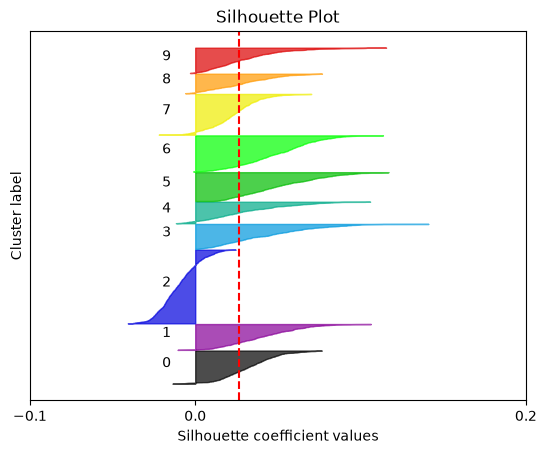

In [18]:
display_silhouette_plots(recipes_vct, recipe_clusters)


### Interpretation

<span style="color:hotpink">
How many clusters did you end up with ?<br>
How do they look ?<br>
</span>

I ended up with 10 clusters. The silhouette plot shows that they are not very well separated. The average silhouette score (the red dashed line) is only about 0.03, which is very close to 0, meaning many recipes sit near the border between clusters. Cluster 2, the largest one, looks the worst its bar extends into negative values, so many of its recipes may belong better to another cluster. This makes sense because it contains generic staples (salt, onions, garlic, black pepper, rice) that appear in many cuisines. Clusters 3, 5, 6 and 9 look the best, with higher scores that mostly pass the average line. The scores are low overall, but this is common for text data, because TF-IDF vectors have hundreds of dimensions and most recipes share common ingredients. So the clusters are not sharply separated, but they are still meaningful, as the cluster centers showed clear cuisines. If we wanted to improve them we could try a different number of clusters, remove very common ingredients, or try another clustering method.

## Recipe Completion

Ok. On to the main event.

Let's create some recipes.

We'll do this using a technique similar to what is used for movie/product recommendations. Given an initial set of ingredients, we'll look at recipes that have similar ingredients and "recommend" additional ingredients.

We already have all of the recipes in our dataset encoded as `tf-idf` vectors. The rest of our algorithm will be something like:
1. Start with an initial set of ingredients
2. Encode ingredients
3. Find a set of recipes that are similar to our list of ingredients
4. Find common ingredients that are in the similar recipes, but not in our list of ingredients
5. Pick representative ingredient to add to recipe
6. Repeat

Let's start.

### 1. Initial list of ingredients

This is just a string with ingredients:

In [19]:
recipe_seed_str = "tofu" # feel free to change this

### 2. Encode ingredients

Transform the string into a `tf-idf` vector using the `transofrm()` function from the pre-fitted `TfidfVectorizer` object:

In [20]:
# TODO: transform string into sparse vector
recipe_seed_vct = TFIDF.transform([recipe_seed_str])

print("Seed vector shape:", recipe_seed_vct.shape)

seed_words = TFIDF.inverse_transform(recipe_seed_vct)
print("Words the vectorizer recognized:", seed_words)

Seed vector shape: (1, 519)
Words the vectorizer recognized: [array(['tofu'], dtype='<U27')]


### 3. Find similar recipes

The meat of the algorithm. No pun intended.

In order to find similar recipes, we'll first calculate the distance between our current list of ingredients and all recipes in our dataset.

We can start with euclidean distance and later try other kinds, but the overall processing will be the same:

1. Start with an empty list to store distances
2. Loop over the `tf-idf` recipe vectors and for each vector:
   1. Subtract the ingredient list
   2. Square the difference (to square a sparse matrix `A`, use `A.multiply(A)`)
   3. Sum the terms of the result
   4. Take the square root of the sum
   5. Append to distance list
3. Find the indices of the smallest distances (this operation is called `argsort` and will give us the indices of the recipes that are most similar to our list of ingredients)
4. Check the recipes to see if they are indeed similar (`inverse_transform()` the vectors at the indices calculated above)

In [22]:
# argsort a list (get sequence of indices that would sort the list)
# https://stackoverflow.com/a/3382369
def argsort(L, reverse=False):
  L = L[0] if len(L) == 1 else L
  return sorted(range(len(L)), key=L.__getitem__, reverse=reverse)

In [23]:
# TODO: list to keep distances
recipe_distances = []

# TODO: loop over vectors and append euclidean distances to list
num_recipe_rows = recipe_vectors.shape[0]

for row_index in range(num_recipe_rows):
    recipe_row = recipe_vectors[row_index]
    difference = recipe_row - recipe_seed_vct
    squared_difference = difference.multiply(difference)
    sum_of_squares = squared_difference.sum()
    distance = sum_of_squares ** 0.5
    recipe_distances.append(distance)

# TODO: argsort list of distances to find indices of similar recipes
similar_indices = argsort(recipe_distances)
closest_indices = similar_indices[:4]
print("Indices of closest recipes:", closest_indices)

# TODO: check first 4 recipes
for recipe_index in closest_indices:
    closest_vector = recipe_vectors[recipe_index]
    recipe_words = TFIDF.inverse_transform(closest_vector)
    print("Recipe", recipe_index, "distance:", recipe_distances[recipe_index])
    print(recipe_words[0])

Indices of closest recipes: [4052, 1771, 1289, 2231]
Recipe 4052 distance: 0.9755890410355214
['black_pepper' 'vinegar' 'vegetable_oil' 'rice' 'soy_sauce' 'onion'
 'carrots' 'sesame_oil' 'tofu']
Recipe 1771 distance: 0.979821166910577
['eggs' 'water' 'garlic' 'fish_sauce' 'tomatoes' 'onions' 'cooking_oil'
 'tofu']
Recipe 1289 distance: 0.9896312021900375
['sugar' 'sesame_seeds' 'garlic' 'soy_sauce' 'scallions' 'sesame_oil'
 'red_pepper' 'tofu']
Recipe 2231 distance: 0.9928713653069527
['sriracha' 'soy_sauce' 'ginger' 'scallions' 'sesame_oil' 'tofu']


### 4. Find ingredients to recommend

We have a way to get a set of similar recipes with similar ingredients, and now want to find a *meaningful*, or *representative*, ingredient to add to our ingredients list.

Let's consider ingredients in the $16$ most similar recipes. What we are trying to do is find an ingredient that is in a lot of these recipes, but not yet in our list of ingredients.

There are many possible ways of doing this. We could count the number of times different ingredients show up in these $16$ recipes using Python dictionaries and/or sets, but what we're trying to do here is very similar to what a `TfidfVectorizer` does: calculate relative importance of terms in a series of documents.

Let's re-encode these $16$ recipes using their own separate `TfidfVectorizer`, then sum the importance of each ingredient and look at ingredients with the highest importance scores.

We could re-use the vectors/scores from the original `TfidfVectorizer`, but they're gonna be influenced by the relative frequencies of all of the ingredients that showed up in all of the recipes. Using a separate vectorizer is a little bit more precise.

The steps we need to take are:

1. Separate the $16$ recipes most similar to our list of ingredients
   1. We have lots of representations of our recipes, but `recipes` (list of strings) might be the easiest one to use here
2. Create a new `TfidfVectorizer` and encode the $16$ recipes
3. Sum the resulting vectors by column to get overall importance scores for each ingredient/token
4. Convert resulting vector to a list using `A.tolist()[0]`
5. `argsort` the importance scores to get sequence of ingredient indices ordered from most to least important
6. Find the most important ingredient that isn't on the ingredient list

In [24]:
# TODO: Get 16 most similar recipes
recipes = recipe_strings
top_16_indices = similar_indices[:16]

top_16_recipes = []
for recipe_index in top_16_indices:
    recipe_text = recipes[recipe_index]
    top_16_recipes.append(recipe_text)

# TODO: Encode the 16 recipes
local_tfidf = TfidfVectorizer()
top_16_vectors = local_tfidf.fit_transform(top_16_recipes)

# TODO: Sum the recipe vectors by column to get ingredient importance scores
summed_vector = top_16_vectors.sum(axis=0)

# TODO: Convert sparse vector to regular list with A.tolist()[0]
importance_scores = summed_vector.tolist()[0]

# TODO: argsort the importance scores
indices_by_importance = argsort(importance_scores, reverse=True)

# TODO: Find most important ingredient not yet on the list of ingredients
local_vocab = local_tfidf.get_feature_names_out()
seed_ingredients = recipe_seed_str.split(" ")

recommended_ingredient = None
for ingredient_index in indices_by_importance:
    candidate = local_vocab[ingredient_index]
    if candidate not in seed_ingredients:
        recommended_ingredient = candidate
        break

print("Top 10 ingredients in similar recipes:")
for ingredient_index in indices_by_importance[:10]:
    print(local_vocab[ingredient_index], importance_scores[ingredient_index])

print("Recommended ingredient to add:", recommended_ingredient)

Top 10 ingredients in similar recipes:
tofu 2.3074144608356413
soy_sauce 2.120674338250387
onion 1.686756616594811
vegetable_oil 1.5989513158912552
garlic 1.5666894029730343
sesame_oil 1.4479455510852546
ginger 1.324581426454713
water 1.310473786351509
salt 1.2818483344914704
black_pepper 0.9375441395099435
Recommended ingredient to add: soy_sauce


### 5. Add ingredient to recipe

This is simply adding a word to `recipe_seed_str`

In [25]:
# TODO: add the first important ingredient to list of ingredients
recipe_seed_str = recipe_seed_str + " " + recommended_ingredient
print("Updated ingredient list:", recipe_seed_str)

Updated ingredient list: tofu soy_sauce


### 6. Repeat (Optional)

Now we can repeat this process until we get an empty list of important ingredients: 
1. Encode current recipe
2. Find similar recipes
3. Find important ingredients
4. Add important ingredient

Might be helpful to define a couple of functions, like `find_similar_recipes()` and `find_important_ingredients()`...

Only do this step if you're really curious about experimenting with generating unconventional ingredient lists. It's not going to be graded.